# 01 · Dados: NSL-KDD

Neste notebook a gente baixa o **NSL-KDD**, entende o que tem nele e aplica o mesmo pré-processamento do artigo:

1. Label Encoding nas 3 colunas categóricas (`protocol_type`, `service`, `flag`)
2. `StandardScaler` (média 0, desvio 1)
3. **PCA de 41 → 3 componentes**, porque o circuito quântico tem 3 qubits (1 feature por qubit)

O rótulo é binário: **0 = normal**, **1 = ataque** (todos os tipos de ataque juntos).

In [1]:
import sys
sys.path.insert(0, "../src")  # pra importar o pacote hqdt sem instalar

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

# paleta categórica validada (daltonismo) + estilo discreto
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3b3b38",
    "xtick.color": "#5c5c58", "ytick.color": "#5c5c58",
    "lines.linewidth": 2, "lines.markersize": 8, "figure.dpi": 110,
})

In [2]:
from hqdt.data import load, Preprocessor, CATEGORICAL

train = load("train")   # baixa pra ../data na primeira vez
test = load("test")
print("KDDTrain+:", train.shape, "| KDDTest+:", test.shape)
train.head()

KDDTrain+: (125973, 44) | KDDTest+: (22544, 44)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack,difficulty,label
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20,0
1,0,udp,other,SF,146,0,0,0,0,0,...,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15,0
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19,1
3,0,tcp,http,SF,232,8153,0,0,0,0,...,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21,0
4,0,tcp,http,SF,199,420,0,0,0,0,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21,0


## Balanço das classes

O NSL-KDD é quase balanceado no treino. O arquivo de teste oficial (`KDDTest+`) tem mais ataques **e tipos de ataque que não aparecem no treino**, por isso ele é bem mais difícil.

In [3]:
resumo = pd.DataFrame({
    "treino": train["label"].value_counts(normalize=True),
    "teste": test["label"].value_counts(normalize=True),
}).rename(index={0: "normal", 1: "ataque"})
(resumo * 100).round(1)

,treino,teste
label,,
normal,53.5,43.1
ataque,46.5,56.9


In [4]:
novos = set(test["attack"]) - set(train["attack"])
print(f"{len(novos)} tipos de ataque só aparecem no teste:", sorted(novos))
print("\nTop 10 tipos de ataque no treino:")
train.loc[train["label"] == 1, "attack"].value_counts().head(10)

17 tipos de ataque só aparecem no teste: ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']

Top 10 tipos de ataque no treino:


attack
neptune        41214
satan           3633
ipsweep         3599
portsweep       2931
smurf           2646
nmap            1493
back             956
teardrop         892
warezclient      890
pod              201
Name: count, dtype: int64

## Pré-processamento

O `Preprocessor` é ajustado **só no treino** e depois aplicado no teste, pra não vazar informação do teste pro modelo.

In [5]:
prep = Preprocessor(n_components=3).fit(train)
X_train = prep.transform(train)
y_train = train["label"].to_numpy()

var = prep.pca_.explained_variance_ratio_
print("Variância explicada por componente:", (var * 100).round(1), "%")
print(f"Total com 3 componentes: {var.sum()*100:.1f}%")

Variância explicada por componente: [19.3 12.9  7. ] %
Total com 3 componentes: 39.3%


Com 3 componentes o PCA guarda só uma parte da variância das 41 features. Esse é o preço de caber em 3 qubits, e é uma limitação que o próprio artigo comenta.

## Como as classes ficam no espaço do PCA

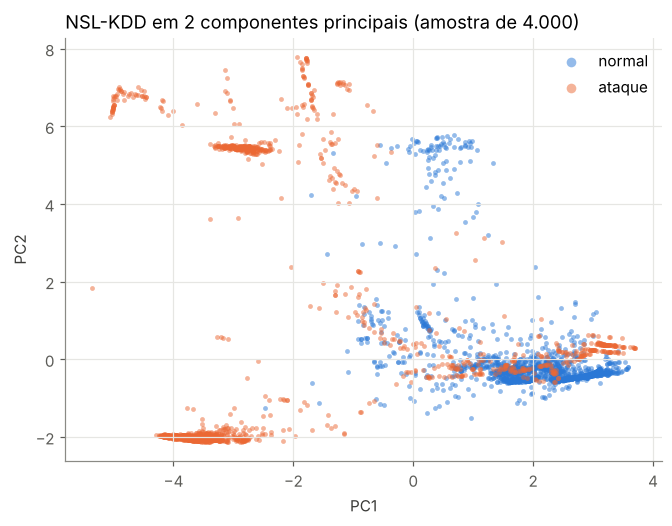

In [6]:
rng = np.random.default_rng(0)
idx = rng.choice(len(X_train), 4000, replace=False)
fig, ax = plt.subplots(figsize=(7, 5))
for label, nome, cor in [(0, "normal", CORES[0]), (1, "ataque", CORES[1])]:
    m = y_train[idx] == label
    ax.scatter(X_train[idx][m, 0], X_train[idx][m, 1], s=10, alpha=0.5, color=cor, label=nome, linewidths=0)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("NSL-KDD em 2 componentes principais (amostra de 4.000)", loc="left")
ax.legend(frameon=False, markerscale=2)
plt.show()

Dá pra ver que as classes se separam bem em boa parte do espaço, mas tem uma região misturada. É nessa região que a árvore precisa trabalhar.